# 04 — Parties, Coalitions/Federations & 2nd Round (Runoff) Transfer Simulations
**Political Aggregation Structure (`agr`, `fed`) & Runoff Mathematical Modeling**

Since no candidate exceeded 50% + 1 of valid votes in the 1st round (**Flavio Bolsonaro**: `47.03%` / `56,104,503` votes; **Lula**: `45.16%` / `53,879,538` votes), the election advances to a **2nd Round (Runoff)**.

This notebook examines:
1. **Coalitions, Federations & Isolated Parties**: How the 12 candidacies are structured across `Coligações` (`tp="c"`), `Federações` (`FE BRASIL`: PT/PC do B/PV), and `Partidos Isolados` (`tp="i"`).
2. **The "Kingmaker" Pool (`9,316,747` Eliminated Candidate Votes)**: Detailed breakdown of the 3rd–12th place votes (led by **Escritor Augusto Cury** `3.45M`, **Renan Santos** `2.68M`, **Ronaldo Caiado** `2.61M`, and **Zema** `0.33M`) relative to the `2,224,965` vote gap between 1st and 2nd place.
3. **2nd-Round Sensitivity Matrix & Indifference Curve**: 2D heatmap calculating the exact runoff margin across all transfer rates of third-party voters to Lula vs Flavio Bolsonaro.
4. **Simulated Runoff Realignment Scenarios**: Projected 2nd-round outcomes under five concrete political realignment hypotheses.

In [1]:
%matplotlib inline
import json
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "data").exists() and (REPO_ROOT.parent / "data").exists():
    REPO_ROOT = REPO_ROOT.parent

DATA_DIR = REPO_ROOT / "data"
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 120
sns.set_theme(style="whitegrid")

latest_path = sorted(DATA_DIR.glob("presidente_br_*.json"))[-1]
doc = json.loads(latest_path.read_text(encoding="utf-8"))
carg = doc["data"]["carg"][0]

fed_map = {f["n"]: f for f in carg.get("fed", [])}

agr_rows = []
for agr in carg["agr"]:
    par = agr["par"][0]
    cand = par["cand"][0]
    vice = cand["vs"][0]
    parties_in_comp = [p.strip() for p in agr.get("com", par["sg"]).split("/")]
    nfed = par.get("nfed", "")
    fed_name = fed_map[nfed]["nm"] if nfed in fed_map else "—"
    agr_rows.append({
        "rank": int(cand["seq"]),
        "candidate": cand["nmu"],
        "head_party": par["sg"],
        "vice_candidate": vice["nmu"],
        "vice_party": vice["sgp"],
        "cross_party_ticket": par["sg"] != vice["sgp"],
        "agr_type": "Coligação" if agr["tp"] == "c" else "Partido Isolado",
        "agr_name": agr["nm"],
        "composition": agr["com"],
        "party_count": len(parties_in_comp),
        "federation": fed_name,
        "votes": int(cand["vap"]),
        "vote_share_pct": float(cand["pvapn"].replace(",", ".")),
    })

df_agr = pd.DataFrame(agr_rows).sort_values("rank").reset_index(drop=True)
df_agr[[
    "rank", "candidate", "head_party", "vice_party", "agr_type",
    "party_count", "composition", "votes", "vote_share_pct"
]]

,rank,candidate,head_party,vice_party,agr_type,party_count,composition,votes,vote_share_pct
0,1,FLAVIO BOLSONARO,PL,PL,Partido Isolado,1,PL,56104503,47.027772
1,2,LULA,PT,PSB,Coligação,7,PSB / PDT / PCDOB / PT / PV / PSOL / REDE,53879538,45.162768
2,3,ESCRITOR AUGUSTO CURY,AVANTE,AVANTE,Coligação,2,AGIR / AVANTE,3448569,2.890651
3,4,RENAN SANTOS,MISSÃO,MISSÃO,Partido Isolado,1,MISSÃO,2675887,2.242975
4,5,RONALDO CAIADO,PSD,PSD,Partido Isolado,1,PSD,2605148,2.183680
5,6,ZEMA,NOVO,NOVO,Partido Isolado,1,NOVO,326488,0.273668
6,7,SAMARA,UP,UP,Partido Isolado,1,UP,122911,0.103026
7,8,HERTZ DIAS,PSTU,PSTU,Partido Isolado,1,PSTU,43103,0.036130
8,9,CLARIANA BARAO,DC,DC,Partido Isolado,1,DC,40043,0.033565
9,10,EDMILSON COSTA,PCB,PCB,Partido Isolado,1,PCB,22693,0.019022


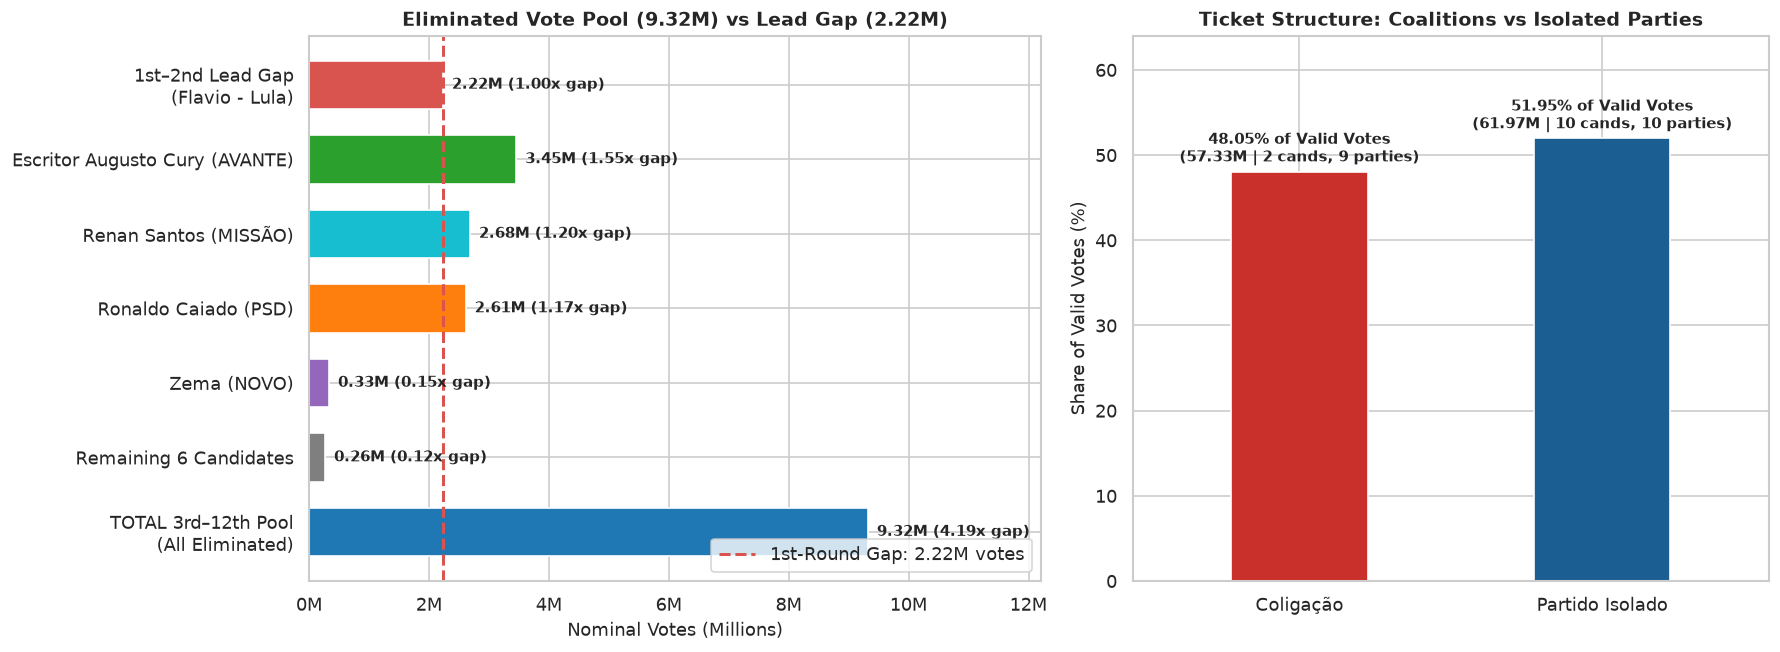

In [2]:
# Graph 1: Kingmaker Pool Breakdown vs 1st-Round Lead Gap (2.22M Votes)
flavio_v = df_agr.loc[0, "votes"]
lula_v = df_agr.loc[1, "votes"]
lead_gap = flavio_v - lula_v
third_party_df = df_agr.iloc[2:].copy()
third_party_total = third_party_df["votes"].sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [1.15, 1]})

# Left: Eliminated candidates' votes compared to the 2.22M gap
pool_items = [
    ("1st–2nd Lead Gap\n(Flavio - Lula)", lead_gap, "#d9534f"),
    ("Escritor Augusto Cury (AVANTE)", third_party_df.iloc[0]["votes"], "#2ca02c"),
    ("Renan Santos (MISSÃO)", third_party_df.iloc[1]["votes"], "#17becf"),
    ("Ronaldo Caiado (PSD)", third_party_df.iloc[2]["votes"], "#ff7f0e"),
    ("Zema (NOVO)", third_party_df.iloc[3]["votes"], "#9467bd"),
    ("Remaining 6 Candidates", third_party_df.iloc[4:]["votes"].sum(), "#7f7f7f"),
    ("TOTAL 3rd–12th Pool\n(All Eliminated)", third_party_total, "#1f77b4"),
][::-1]

ax1.barh([p[0] for p in pool_items], [p[1] / 1e6 for p in pool_items], color=[p[2] for p in pool_items], height=0.65)
ax1.axvline(lead_gap / 1e6, color="#d9534f", linestyle="--", linewidth=1.8, label=f"1st-Round Gap: {lead_gap/1e6:.2f}M votes")

for idx, (label, val, _) in enumerate(pool_items):
    ratio = val / lead_gap
    ax1.text(val / 1e6 + 0.15, idx, f"{val/1e6:.2f}M ({ratio:.2f}x gap)", va="center", fontsize=9, fontweight="bold")

ax1.set_xlim(0, 12.2)
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}M"))
ax1.set_xlabel("Nominal Votes (Millions)", fontsize=10.5)
ax1.set_title("Eliminated Vote Pool (9.32M) vs Lead Gap (2.22M)", fontsize=11.5, fontweight="bold")
ax1.legend(loc="lower right", frameon=True)

# Right: Coalition vs Isolated Party Vote Share & Party Count
type_grp = df_agr.groupby("agr_type", as_index=False).agg(
    total_votes=("votes", "sum"),
    vote_share=("vote_share_pct", "sum"),
    candidates=("candidate", "count"),
    total_parties=("party_count", "sum")
)

bars2 = ax2.bar(type_grp["agr_type"], type_grp["vote_share"], color=["#c9302c", "#1b5e91"], width=0.45)
for bar, (_, r) in zip(bars2, type_grp.iterrows()):
    h = bar.get_height()
    ax2.text(
        bar.get_x() + bar.get_width() / 2, h + 1.2,
        f"{h:.2f}% of Valid Votes\n({r['total_votes']/1e6:.2f}M | {r['candidates']} cands, {r['total_parties']} parties)",
        ha="center", fontsize=8.8, fontweight="bold"
    )
ax2.set_xlim(-0.55, 1.55)
ax2.set_ylim(0, 64)
ax2.set_ylabel("Share of Valid Votes (%)", fontsize=10.5)
ax2.set_title("Ticket Structure: Coalitions vs Isolated Parties", fontsize=11.5, fontweight="bold")

plt.tight_layout()
plt.show()

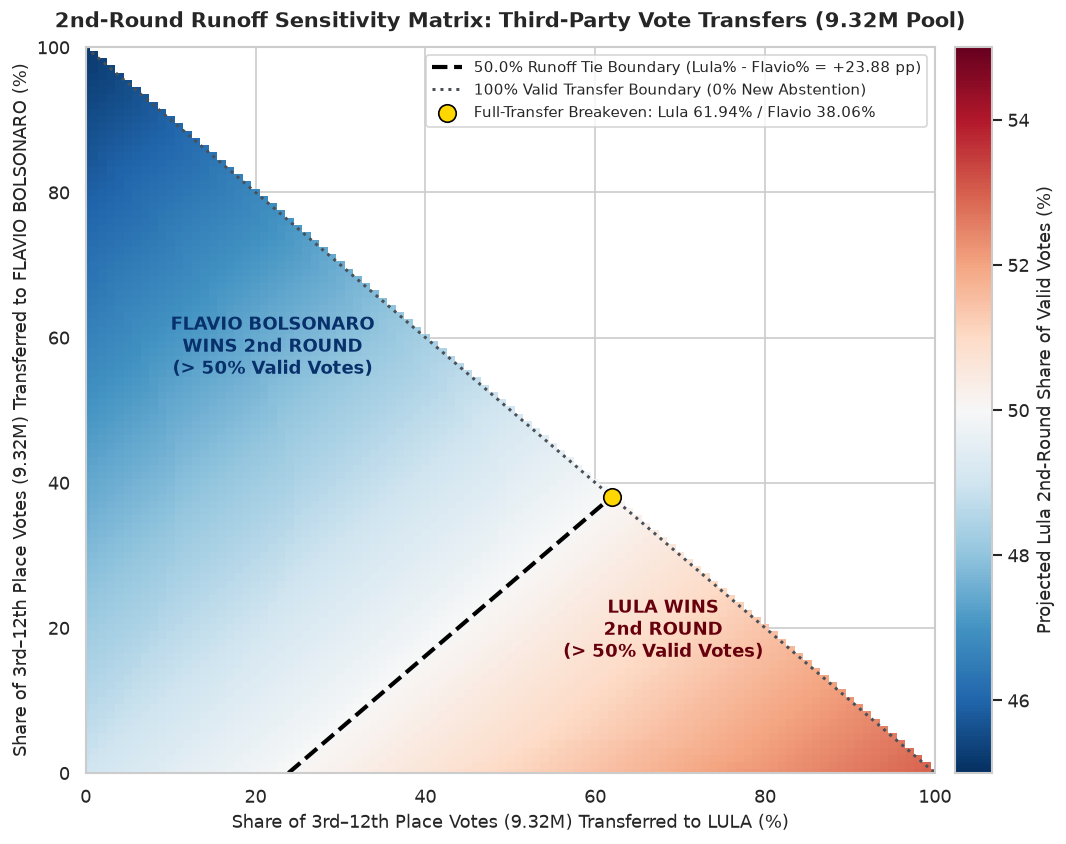

In [3]:
# Graph 2: 2nd-Round Sensitivity Heatmap & Indifference Boundary
# Model: Flavio and Lula retain their 1st-round base; third_party_total (9,316,747 votes)
# splits with share alpha -> Lula, beta -> Flavio, and (1 - alpha - beta) -> Abstention/Blank/Null.
grid_n = 101
lula_transfer_pct = np.linspace(0, 100, grid_n)    # % of 9.32M pool going to Lula
flavio_transfer_pct = np.linspace(0, 100, grid_n)  # % of 9.32M pool going to Flavio
L_grid, F_grid = np.meshgrid(lula_transfer_pct, flavio_transfer_pct)

# Valid combinations require L_grid + F_grid <= 100%
valid_mask = (L_grid + F_grid) <= 100.0001
lula_runoff_votes = lula_v + (L_grid / 100.0) * third_party_total
flavio_runoff_votes = flavio_v + (F_grid / 100.0) * third_party_total
lula_runoff_share = np.where(
    valid_mask,
    lula_runoff_votes / (lula_runoff_votes + flavio_runoff_votes) * 100.0,
    np.nan,
)

# Exact tie threshold when 100% of third-party voters cast valid runoff votes (L + F = 100)
lula_min_share_no_abst = (lead_gap + third_party_total) / (2 * third_party_total) * 100
flavio_min_share_no_abst = 100.0 - lula_min_share_no_abst

fig, ax = plt.subplots(figsize=(9.5, 7.2))
cmap = plt.cm.RdBu_r
im = ax.pcolormesh(L_grid, F_grid, lula_runoff_share, cmap=cmap, vmin=45.0, vmax=55.0, shading="auto")
cbar = fig.colorbar(im, ax=ax, pad=0.02)
cbar.set_label("Projected Lula 2nd-Round Share of Valid Votes (%)", fontsize=10.5)

# Plot 50% tie line: lula_v + (L/100)*P = flavio_v + (F/100)*P  =>  L - F = (flavio_v - lula_v)/P * 100
gap_pct_of_pool = (lead_gap / third_party_total) * 100.0  # 23.881%
l_line = np.linspace(gap_pct_of_pool, (100 + gap_pct_of_pool) / 2, 200)
f_line = l_line - gap_pct_of_pool
ax.plot(l_line, f_line, color="black", linestyle="--", linewidth=2.5, label=f"50.0% Runoff Tie Boundary (Lula% - Flavio% = +{gap_pct_of_pool:.2f} pp)")

# Plot 0% abstention boundary (L + F = 100%)
ax.plot([0, 100], [100, 0], color="#495057", linestyle=":", linewidth=1.8, label="100% Valid Transfer Boundary (0% New Abstention)")
ax.scatter([lula_min_share_no_abst], [flavio_min_share_no_abst], color="#ffd700", edgecolors="black", s=110, zorder=6,
           label=f"Full-Transfer Breakeven: Lula {lula_min_share_no_abst:.2f}% / Flavio {flavio_min_share_no_abst:.2f}%")

ax.text(22, 55, "FLAVIO BOLSONARO\nWINS 2nd ROUND\n(> 50% Valid Votes)", fontsize=11, fontweight="bold", color="#08306b", ha="center")
ax.text(68, 16, "LULA WINS\n2nd ROUND\n(> 50% Valid Votes)", fontsize=11, fontweight="bold", color="#67000d", ha="center")

ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_xlabel("Share of 3rd–12th Place Votes (9.32M) Transferred to LULA (%)", fontsize=10.5)
ax.set_ylabel("Share of 3rd–12th Place Votes (9.32M) Transferred to FLAVIO BOLSONARO (%)", fontsize=10.5)
ax.set_title("2nd-Round Runoff Sensitivity Matrix: Third-Party Vote Transfers (9.32M Pool)", fontsize=12.5, fontweight="bold", pad=12)
ax.legend(loc="upper right", frameon=True, fontsize=9)

plt.tight_layout()
plt.show()

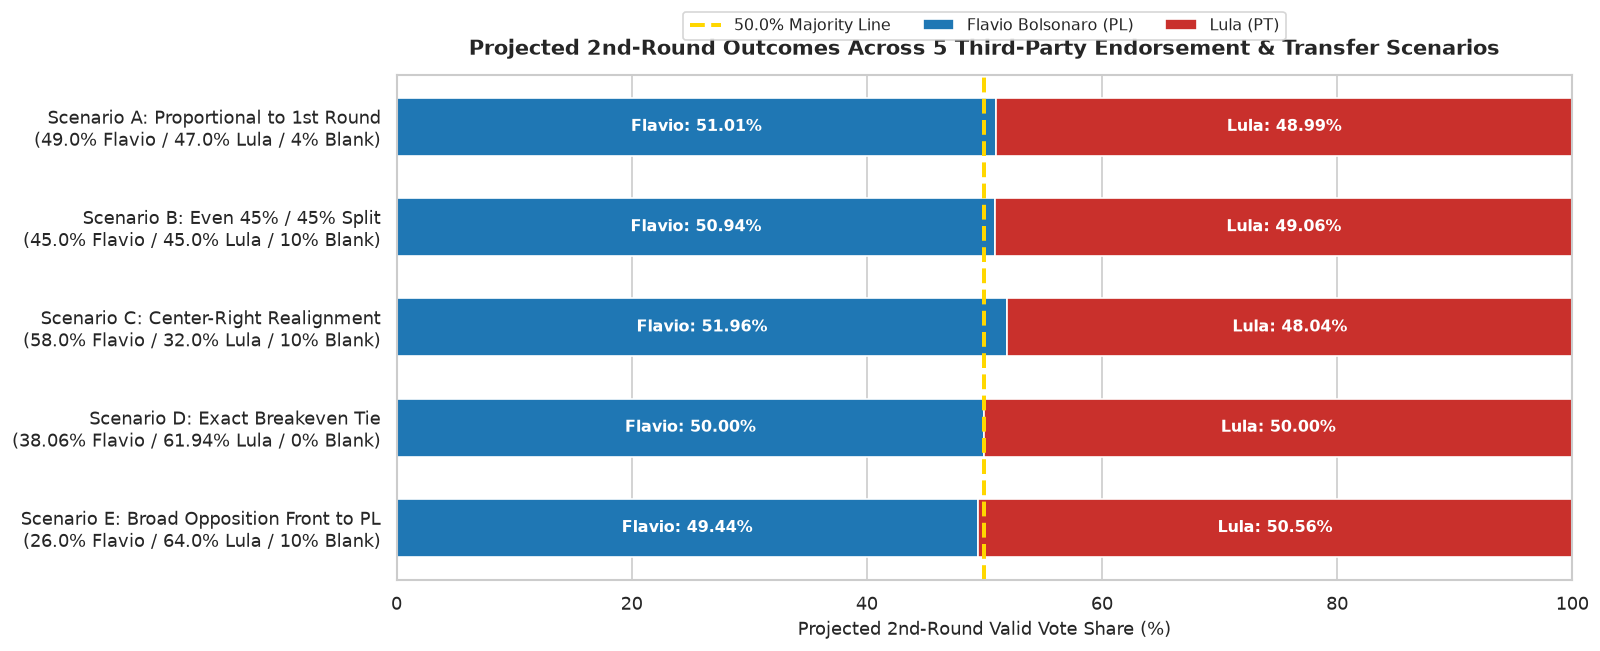

In [4]:
# Graph 3: Concrete 2nd-Round Transfer Scenarios Simulation
scenarios = [
    ("Scenario A: Proportional to 1st Round\n(49.0% Flavio / 47.0% Lula / 4% Blank)", 0.490, 0.470),
    ("Scenario B: Even 45% / 45% Split\n(45.0% Flavio / 45.0% Lula / 10% Blank)", 0.450, 0.450),
    ("Scenario C: Center-Right Realignment\n(58.0% Flavio / 32.0% Lula / 10% Blank)", 0.580, 0.320),
    ("Scenario D: Exact Breakeven Tie\n(38.06% Flavio / 61.94% Lula / 0% Blank)", flavio_min_share_no_abst / 100, lula_min_share_no_abst / 100),
    ("Scenario E: Broad Opposition Front to PL\n(26.0% Flavio / 64.0% Lula / 10% Blank)", 0.260, 0.640),
]

sim_rows = []
for label, f_rate, l_rate in scenarios:
    f_tot = flavio_v + f_rate * third_party_total
    l_tot = lula_v + l_rate * third_party_total
    valid_tot = f_tot + l_tot
    sim_rows.append({
        "Scenario": label,
        "Flavio_Pct": f_tot / valid_tot * 100,
        "Lula_Pct": l_tot / valid_tot * 100,
        "Margin_Votes": f_tot - l_tot,
    })

df_sim = pd.DataFrame(sim_rows)[::-1].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(13.5, 5.6))
ax.barh(df_sim["Scenario"], df_sim["Flavio_Pct"], color="#1f77b4", edgecolor="white", height=0.58, label="Flavio Bolsonaro (PL)")
ax.barh(df_sim["Scenario"], df_sim["Lula_Pct"], left=df_sim["Flavio_Pct"], color="#c9302c", edgecolor="white", height=0.58, label="Lula (PT)")
ax.axvline(50.0, color="#ffd700", linestyle="--", linewidth=2.4, label="50.0% Majority Line")

for idx, row in df_sim.iterrows():
    ax.text(row["Flavio_Pct"] / 2, idx, f"Flavio: {row['Flavio_Pct']:.2f}%", ha="center", va="center", color="white", fontweight="bold", fontsize=9.5)
    ax.text(row["Flavio_Pct"] + row["Lula_Pct"] / 2, idx, f"Lula: {row['Lula_Pct']:.2f}%", ha="center", va="center", color="white", fontweight="bold", fontsize=9.5)

ax.set_xlim(0, 100)
ax.set_xlabel("Projected 2nd-Round Valid Vote Share (%)", fontsize=10.5)
ax.set_title("Projected 2nd-Round Outcomes Across 5 Third-Party Endorsement & Transfer Scenarios", fontsize=12.5, fontweight="bold", pad=12)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.14), ncol=3, frameon=True, fontsize=9.5)

plt.tight_layout()
plt.show()